# Fokker-Planck Equation (Diffusion + Drift in a Potential)

**References:** `Notes/lec_pde.pdf` (Slides 7–9), `Notes/FokkerPlanck.ipynb` (Professor code), `Notes/Quiz2/07_Fokker_Planck_and_Langevin.ipynb`

## Concept & Formulas
Describes how the probability / concentration profile $\rho(x, t)$ evolves under diffusion and an external potential $U(x)$:

- **Continuity Equation (Conservation):** $\frac{\partial \rho}{\partial t} = -\frac{\partial J}{\partial x}$.
- **Total Current:** $J = J_{\text{diffusion}} + J_{\text{drift}} = -D\frac{\partial \rho}{\partial x} - \rho\frac{dU}{dx}$.
- **Fokker-Planck Equation:**
  $$\frac{\partial \rho}{\partial t} = D\frac{\partial^2 \rho}{\partial x^2} + \frac{\partial}{\partial x}\left(\rho \frac{dU}{dx}\right)$$
- **Equilibrium Steady State ($J = 0$):** Relaxes to the Gibbs-Boltzmann distribution $\rho_{\text{eq}}(x) \propto e^{-U(x)/D}$, peaking at the potential minimum.
- **Limitations:** Explicit time stepping requires $\frac{D\Delta t}{\Delta x^2} \le \frac{1}{2}$ and small $\Delta t$ so drift does not cause oscillations.

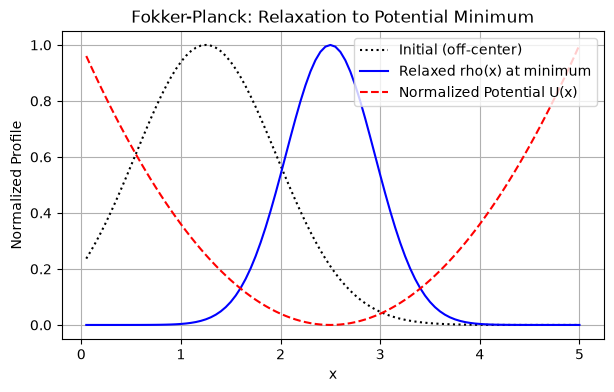

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Quiz 2 Reference Code: Relaxation in Harmonic Potential U(x) = (k/2)*(x - L/2)^2
dt = 0.01; dx = 0.05; D = 0.02; t_end = 100.0
N = 100; L = N * dx
t = np.arange(dt, t_end + dt, dt)
x = np.arange(1, N + 1) * dx

k_pot = 0.1
U = (k_pot / 2.0) * (x - L / 2.0)**2
Up = k_pot * (x - L / 2.0)
Up[0] = Up[-1]     # Periodic BC on force

rho = np.exp(-((x - L/4) / 1.0)**2)   # Off-center initial pulse
rho0 = rho.copy()
rho_temp = np.zeros(N)

for step in range(len(t)):
    rho[0] = rho[-1]
    rho[-2] = rho[1]
    rU = rho * Up
    for p in range(1, N - 1):
        diff_term = (D / (dx**2)) * (rho[p+1] + rho[p-1] - 2 * rho[p])
        drift_term = (rU[p+1] - rU[p-1]) / (2.0 * dx)
        rho_temp[p] = rho[p] + dt * (diff_term + drift_term)
    rho = rho_temp.copy()

plt.figure(figsize=(7, 4))
plt.plot(x, rho0 / np.max(rho0), 'k:', label='Initial (off-center)')
plt.plot(x, rho / np.max(rho), 'b-', label='Relaxed rho(x) at minimum')
plt.plot(x, U / np.max(U), 'r--', label='Normalized Potential U(x)')
plt.xlabel('x'); plt.ylabel('Normalized Profile')
plt.title('Fokker-Planck: Relaxation to Potential Minimum')
plt.legend(); plt.grid(True)
plt.show()

---
## Professor's In-Class Code (`Notes/FokkerPlanck.ipynb`)
Exact code from the professor's notebook.

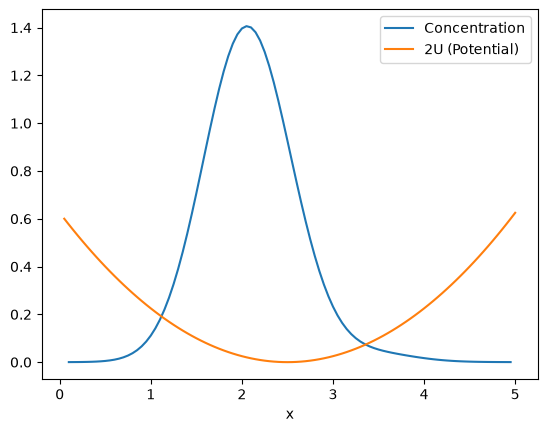

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
dt = 0.01       # Temporal resolution
dx = 0.05       # Spatial resolution
D = 0.02        # Diffusion constant
t_end = 100     # Final time point

N = 100         # Number of grid points
L = N * dx      # System size

# Time and space vectors
t = np.arange(dt, t_end + dt, dt)
x = np.arange(1, N + 1) * dx

k = 0.1         # Sharpness parameter of the potential

# Initialize concentration fields
rho = np.zeros(N)
rho_0 = np.zeros(N)
rho_temp = np.zeros(N)

# Initial condition
rho_0 = np.exp(-((x - L / 4) / 1)**2)
rho = rho_0.copy()

# External potential and its derivative
U = (k / 2) * (x - L / 2)**2
Up = k * (x - L / 2)

# Periodic boundary condition
Up[0] = Up[-1]

# Store concentration at every time step
rho_T = np.zeros((N, len(t)))

# Time evolution
for i in range(len(t)):

    # Periodic boundary conditions
    rho[-1] = rho[1]
    rho[0] = rho[-2]

    # Product of concentration and potential derivative
    rU = rho * Up

    # Update concentration at interior grid points
    for p in range(1, N - 1):

        rho_temp[p] = rho[p] + dt * (D / dx**2 * (rho[p + 1] + rho[p - 1] - 2 * rho[p]) +
            (rU[p + 1] - rU[p - 1]) / (2 * dx)
        )
    # Update concentration
    rho = rho_temp.copy()

    # Store concentration profile
    rho_T[:, i] = rho

plt.plot(x[1:-1], rho_T[1:-1, 1000], label='Concentration')
plt.plot(x, 2 * U, label='2U (Potential)')
plt.legend()
plt.xlabel('x')
plt.show()